# Train StarDist model
This notebook is based on the example code provided by the [StarDist project](https://github.com/stardist/stardist).

Please refer to the [StarDist project](https://github.com/stardist/stardist) for more details.

The original StarDist code is distributed under the [BSD 3-Clause License](https://github.com/stardist/stardist/blob/main/LICENSE.txt).

## 0. Environment Setup

This notebook was developed using Python 3.9.19 on macOS (Apple Silicon: M3/M4) with [Miniforge](https://github.com/conda-forge/miniforge?utm_source=chatgpt.com).

Create a conda environment and install the required packages:

```bash
conda create -n stardist-env python=3.9.19
conda activate stardist-env

pip install tensorflow==2.14 tensorflow-metal==1.1.0 stardist==0.9.1
conda install ipykernel natsort=8.4.0 libcxx=20.1.3
pip install merge-stardist-masks
```

## 1. Import libraries

In [16]:
# Standard libraries
import sys
from glob import glob

# Numerical computation and visualization
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from tqdm import tqdm

# Image processing
from tifffile import imread

# CSBDeep utilities
from csbdeep.utils import Path, normalize

# StarDist
from stardist import fill_label_holes, random_label_cmap, calculate_extents, gputools_available
from stardist.matching import matching, matching_dataset
from stardist.models import Config2D, StarDist2D, StarDistData2D

# Visualization settings
matplotlib.rcParams["image.interpolation"] = "none"
%matplotlib inline
%config InlineBackend.figure_format = "retina"

# Random seed and label colormap
np.random.seed(42)
lbl_cmap = random_label_cmap()

# Check GPU availability
import tensorflow as tf
print("Num GPUs Available:", len(tf.config.experimental.list_physical_devices("GPU")))


Num GPUs Available: 1


## 2. Data

In [ ]:
# Get training images and corresponding mask images
X = sorted(glob('./Data/images_split_merge/*.tif'))
Y = sorted(glob('./Dataroimap_split_merge/*.tif'))

# Check that image and mask filenames match
assert all(Path(x).name==Path(y).name for x,y in zip(X,Y))

In [3]:
# Load training images and masks
X = list(map(imread,X))
Y = list(map(imread,Y))
n_channel = 1 if X[0].ndim == 2 else X[0].shape[-1]

Normalize images and fill small label holes.

In [4]:
axis_norm = (0,1)   # normalize channels independently
# axis_norm = (0,1,2) # normalize channels jointly
if n_channel > 1:
    print("Normalizing image channels %s." % ('jointly' if axis_norm is None or 2 in axis_norm else 'independently'))
    sys.stdout.flush()

X = [normalize(x,1,99.8,axis=axis_norm) for x in tqdm(X)]
Y = [fill_label_holes(y) for y in tqdm(Y)]

100%|██████████| 432/432 [00:00<00:00, 803.51it/s] 


Split into train and validation datasets.

In [5]:
assert len(X) > 1, "not enough training data"
rng = np.random.RandomState(42)
ind = rng.permutation(len(X))
n_val = max(1, int(round(0.15 * len(ind))))
ind_train, ind_val = ind[:-n_val], ind[-n_val:]
X_val, Y_val = [X[i] for i in ind_val]  , [Y[i] for i in ind_val]
X_trn, Y_trn = [X[i] for i in ind_train], [Y[i] for i in ind_train]
print('number of images: %3d' % len(X))
print('- training:       %3d' % len(X_trn))
print('- validation:     %3d' % len(X_val))

number of images: 432
- training:       367
- validation:      65


Training data consists of pairs of input image and label instances.

In [6]:
def plot_img_label(img, lbl, img_title="image", lbl_title="label", **kwargs):
    fig, (ai,al) = plt.subplots(1,2, figsize=(12,5), gridspec_kw=dict(width_ratios=(1.25,1)))
    im = ai.imshow(img, cmap='gray', clim=(0,1))
    ai.set_title(img_title)    
    fig.colorbar(im, ax=ai)
    al.imshow(lbl, cmap=lbl_cmap)
    al.set_title(lbl_title)
    plt.tight_layout()

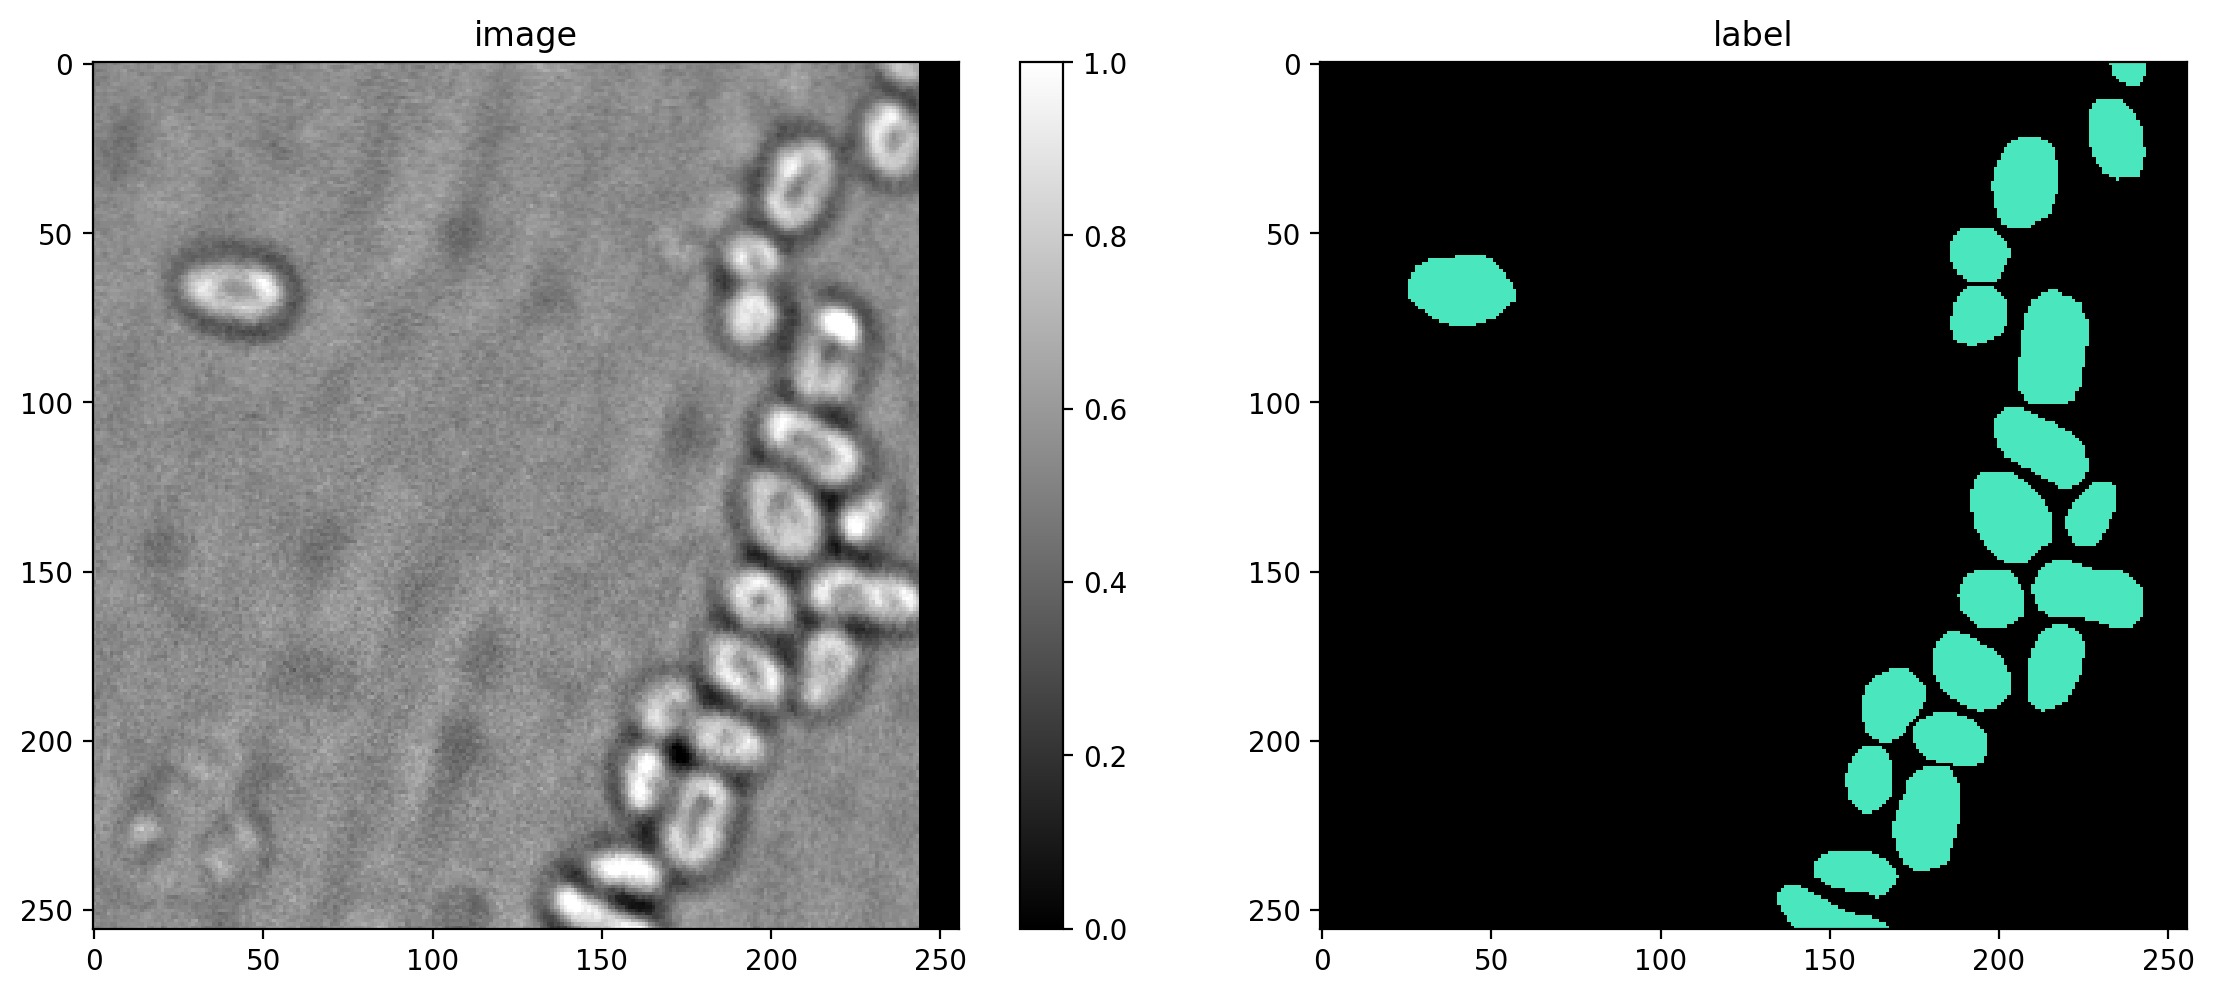

In [7]:
i = min(9, len(X)-1)
img, lbl = X[i], Y[i]
assert img.ndim in (2,3)
img = img if (img.ndim==2 or img.shape[-1]==3) else img[...,0]
plot_img_label(img,lbl)
None;

## 3. Configuration

A `StarDist2D` model is specified via a `Config2D` object.

In [8]:
# Display the Config2D documentation to review the available model configuration parameters
print(Config2D.__doc__)

Configuration for a :class:`StarDist2D` model.

    Parameters
    ----------
    axes : str or None
        Axes of the input images.
    n_rays : int
        Number of radial directions for the star-convex polygon.
        Recommended to use a power of 2 (default: 32).
    n_channel_in : int
        Number of channels of given input image (default: 1).
    grid : (int,int)
        Subsampling factors (must be powers of 2) for each of the axes.
        Model will predict on a subsampled grid for increased efficiency and larger field of view.
    n_classes : None or int
        Number of object classes to use for multi-class prediction (use None to disable)
    backbone : str
        Name of the neural network architecture to be used as backbone.
    kwargs : dict
        Overwrite (or add) configuration attributes (see below).


    Attributes
    ----------
    unet_n_depth : int
        Number of U-Net resolution levels (down/up-sampling layers).
    unet_kernel_size : (int,int)
   

In [9]:
# 32 is a good default choice (see 1_data.ipynb)
n_rays = 64

# Use OpenCL-based computations for data generator during training (requires 'gputools')
use_gpu = False and gputaools_available()

# Predict on subsampled grid for increased efficiency and larger field of view
grid = (8,8)

conf = Config2D (
    n_rays       = n_rays,
    grid         = grid,
    use_gpu      = use_gpu,
    n_channel_in = n_channel,
    train_epochs = 400,
    train_steps_per_epoch = 100,
)
print(conf)
vars(conf)

Config2D(n_dim=2, axes='YXC', n_channel_in=1, n_channel_out=65, train_checkpoint='weights_best.h5', train_checkpoint_last='weights_last.h5', train_checkpoint_epoch='weights_now.h5', n_rays=64, grid=(8, 8), backbone='unet', n_classes=None, unet_n_depth=3, unet_kernel_size=(3, 3), unet_n_filter_base=32, unet_n_conv_per_depth=2, unet_pool=(2, 2), unet_activation='relu', unet_last_activation='relu', unet_batch_norm=False, unet_dropout=0.0, unet_prefix='', net_conv_after_unet=128, net_input_shape=(None, None, 1), net_mask_shape=(None, None, 1), train_shape_completion=False, train_completion_crop=32, train_patch_size=(256, 256), train_background_reg=0.0001, train_foreground_only=0.9, train_sample_cache=True, train_dist_loss='mae', train_loss_weights=(1, 0.2), train_class_weights=(1, 1), train_epochs=400, train_steps_per_epoch=100, train_learning_rate=0.0003, train_batch_size=4, train_n_val_patches=None, train_tensorboard=True, train_reduce_lr={'factor': 0.5, 'patience': 40, 'min_delta': 0}, 

{'n_dim': 2,
 'axes': 'YXC',
 'n_channel_in': 1,
 'n_channel_out': 65,
 'train_checkpoint': 'weights_best.h5',
 'train_checkpoint_last': 'weights_last.h5',
 'train_checkpoint_epoch': 'weights_now.h5',
 'n_rays': 64,
 'grid': (8, 8),
 'backbone': 'unet',
 'n_classes': None,
 'unet_n_depth': 3,
 'unet_kernel_size': (3, 3),
 'unet_n_filter_base': 32,
 'unet_n_conv_per_depth': 2,
 'unet_pool': (2, 2),
 'unet_activation': 'relu',
 'unet_last_activation': 'relu',
 'unet_batch_norm': False,
 'unet_dropout': 0.0,
 'unet_prefix': '',
 'net_conv_after_unet': 128,
 'net_input_shape': (None, None, 1),
 'net_mask_shape': (None, None, 1),
 'train_shape_completion': False,
 'train_completion_crop': 32,
 'train_patch_size': (256, 256),
 'train_background_reg': 0.0001,
 'train_foreground_only': 0.9,
 'train_sample_cache': True,
 'train_dist_loss': 'mae',
 'train_loss_weights': (1, 0.2),
 'train_class_weights': (1, 1),
 'train_epochs': 400,
 'train_steps_per_epoch': 100,
 'train_learning_rate': 0.0003,


In [10]:
if use_gpu:
    from csbdeep.utils.tf import limit_gpu_memory
    # adjust as necessary: limit GPU memory to be used by TensorFlow to leave some to OpenCL-based computations
    limit_gpu_memory(0.8)
    # alternatively, try this:
    # limit_gpu_memory(None, allow_growth=True)

**Note:** The trained `StarDist2D` model will *not* predict completed shapes for partially visible objects at the image boundary if `train_shape_completion=False` (which is the default option).

In [11]:
# Initialize the StarDist model using the specified configuration
model = StarDist2D(conf, name='241128_PY1', basedir='models')

2026-11-19 01:21:46.422010: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M3
2026-11-19 01:21:46.422047: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-11-19 01:21:46.422065: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.92 GB
2026-11-19 01:21:46.422156: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:306] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-11-19 01:21:46.422216: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:272] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Using default values: prob_thresh=0.5, nms_thresh=0.4.


Check if the neural network has a large enough field of view to see up to the boundary of most objects.

In [12]:
# Calculate the median object size along each spatial axis
median_size = calculate_extents(list(Y), np.median)

# Estimate the network's field of view (receptive field)
fov = np.array(model._axes_tile_overlap('YX'))

print(f"median object size:      {median_size}")
print(f"network field of view :  {fov}")

# Warn if the median object size exceeds the network's field of view
if any(median_size > fov):
    print("WARNING: median object size larger than field of view of the neural network.")

2026-11-19 01:21:53.722010: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


median object size:      [210. 219.]
network field of view :  [330 346]


## 4. Data Augmentation

You can define a function/callable that applies augmentation to each batch of the data generator.  
We here use an `augmenter` that applies random rotations, flips, and intensity changes, which are typically sensible for (2D) microscopy images (but you can disable augmentation by setting `augmenter = None`).

In [13]:
# Randomly rotate and flip the image and mask
def random_fliprot(img, mask): 
    assert img.ndim >= mask.ndim
    axes = tuple(range(mask.ndim))
    perm = tuple(np.random.permutation(axes))
    img = img.transpose(perm + tuple(range(mask.ndim, img.ndim))) 
    mask = mask.transpose(perm) 
    for ax in axes: 
        if np.random.rand() > 0.5:
            img = np.flip(img, axis=ax)
            mask = np.flip(mask, axis=ax)
    return img, mask 

# Randomly adjust image intensity
def random_intensity_change(img):
    img = img*np.random.uniform(0.6,2) + np.random.uniform(-0.2,0.2)
    return img

# Combine geometric and intensity augmentations
def augmenter(x, y):
    """Augmentation of a single input/label image pair.
    x is an input image
    y is the corresponding ground-truth label image
    """
    x, y = random_fliprot(x, y)
    x = random_intensity_change(x)
    # add some gaussian noise
    sig = 0.02*np.random.uniform(0,1)
    x = x + sig*np.random.normal(0,1,x.shape)
    return x, y

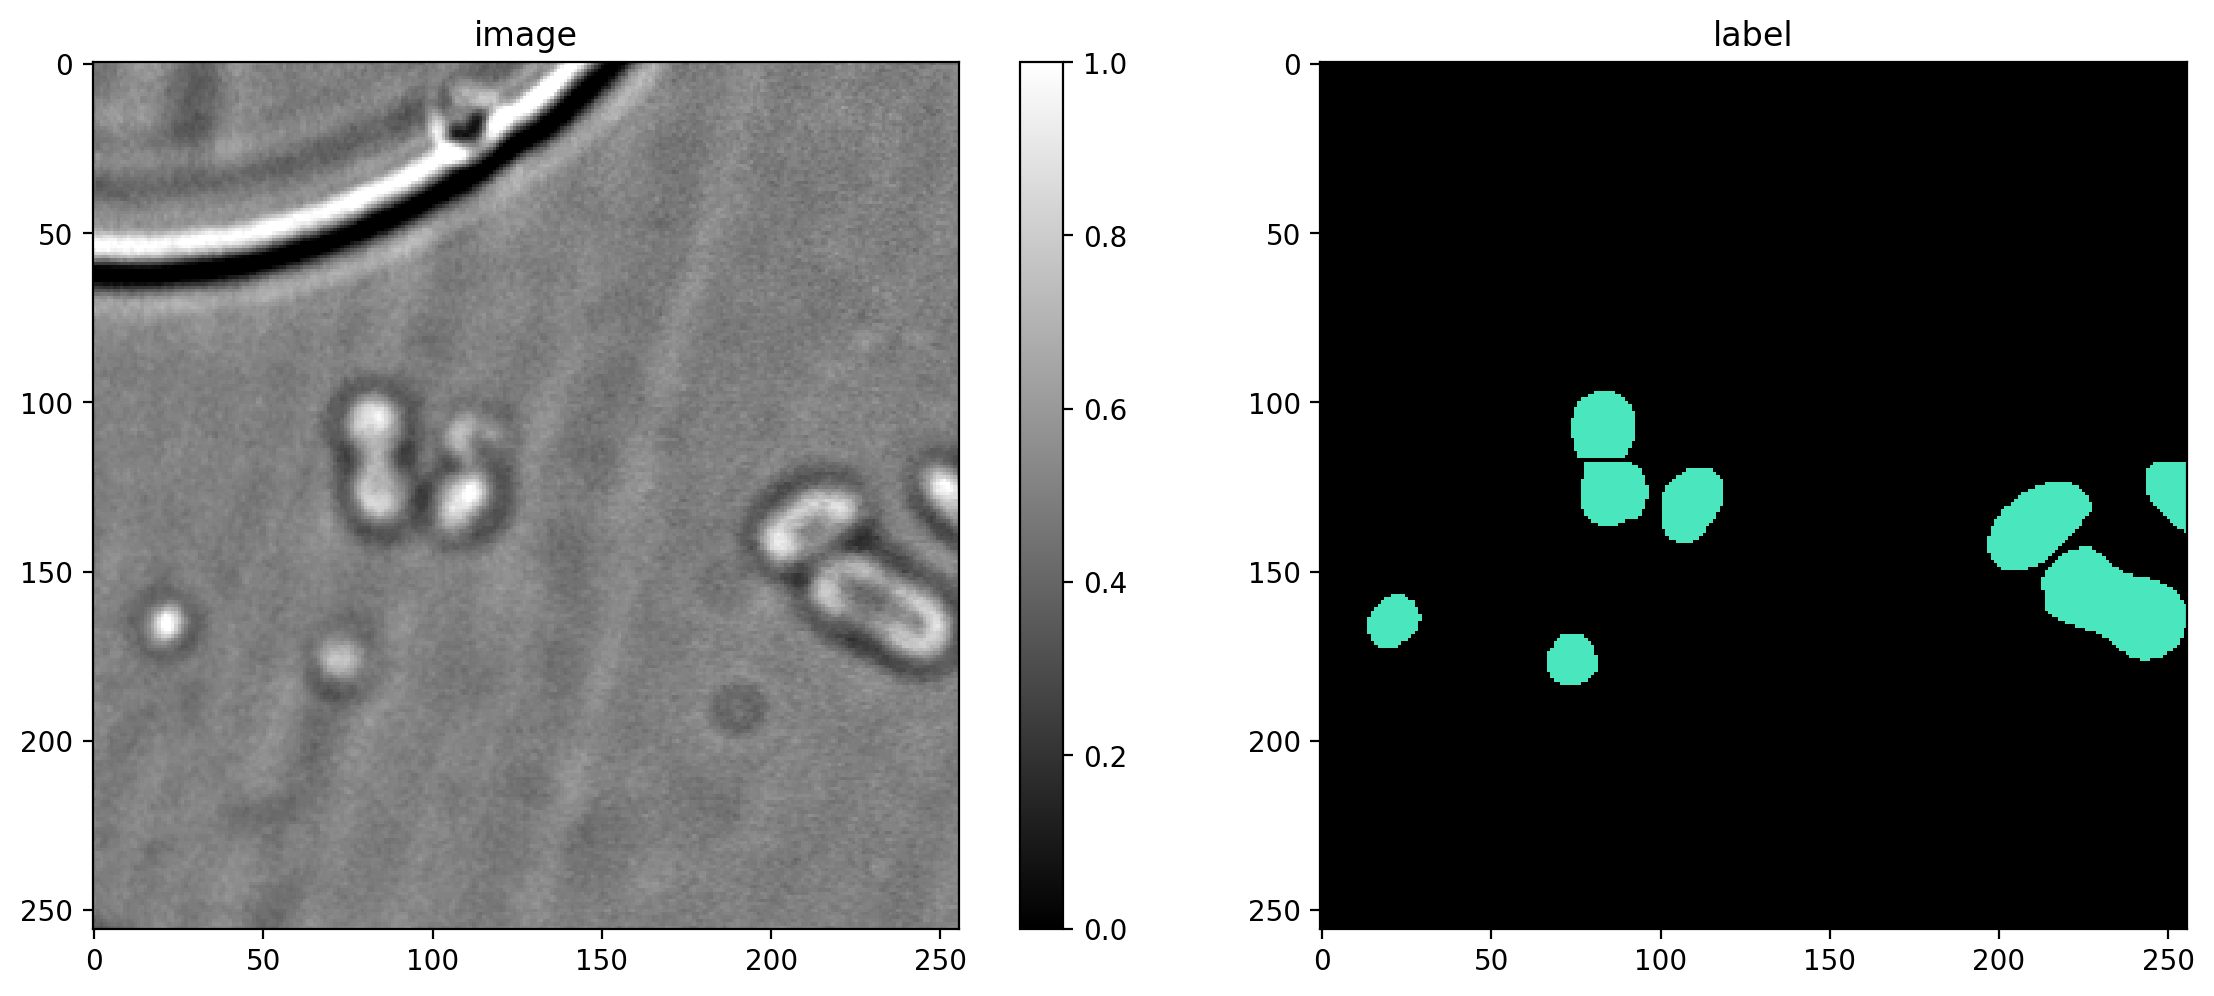

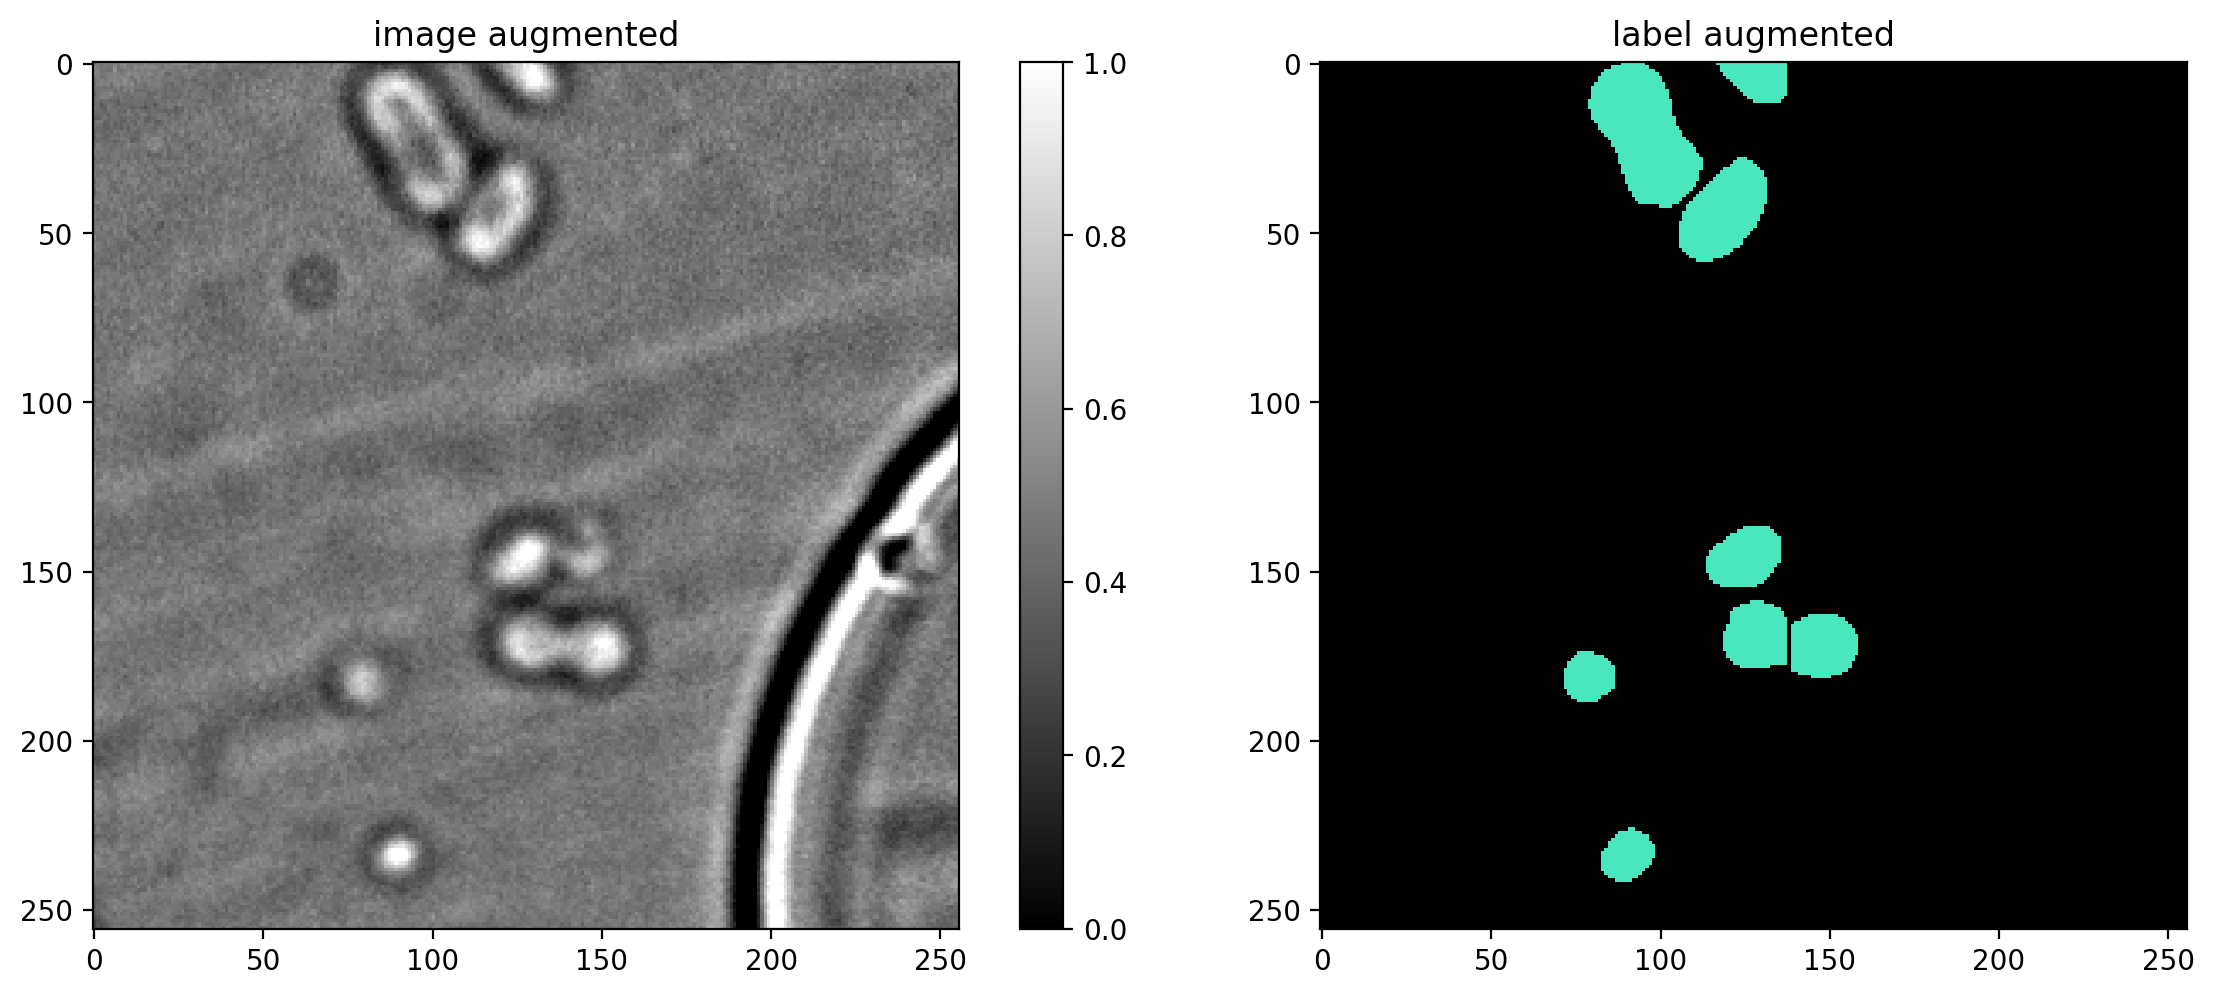

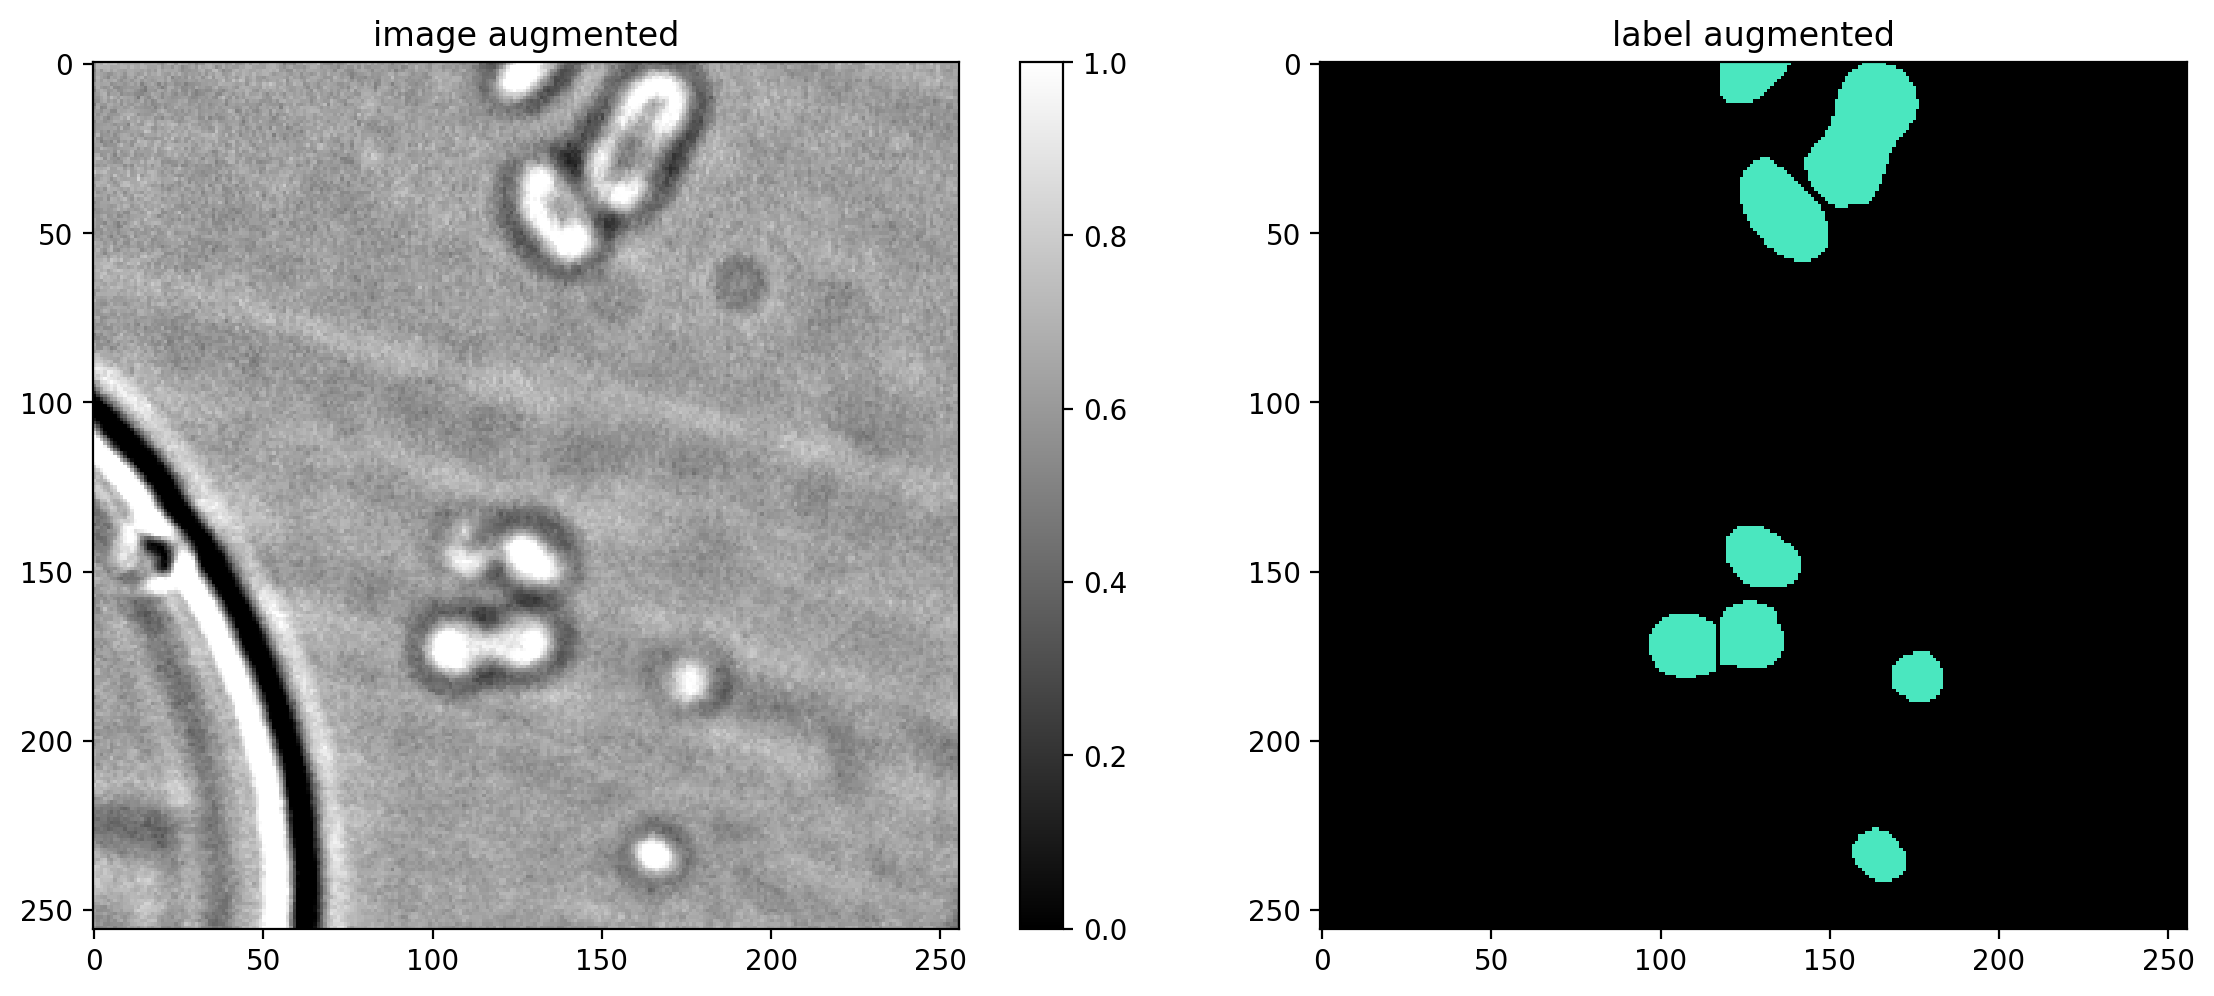

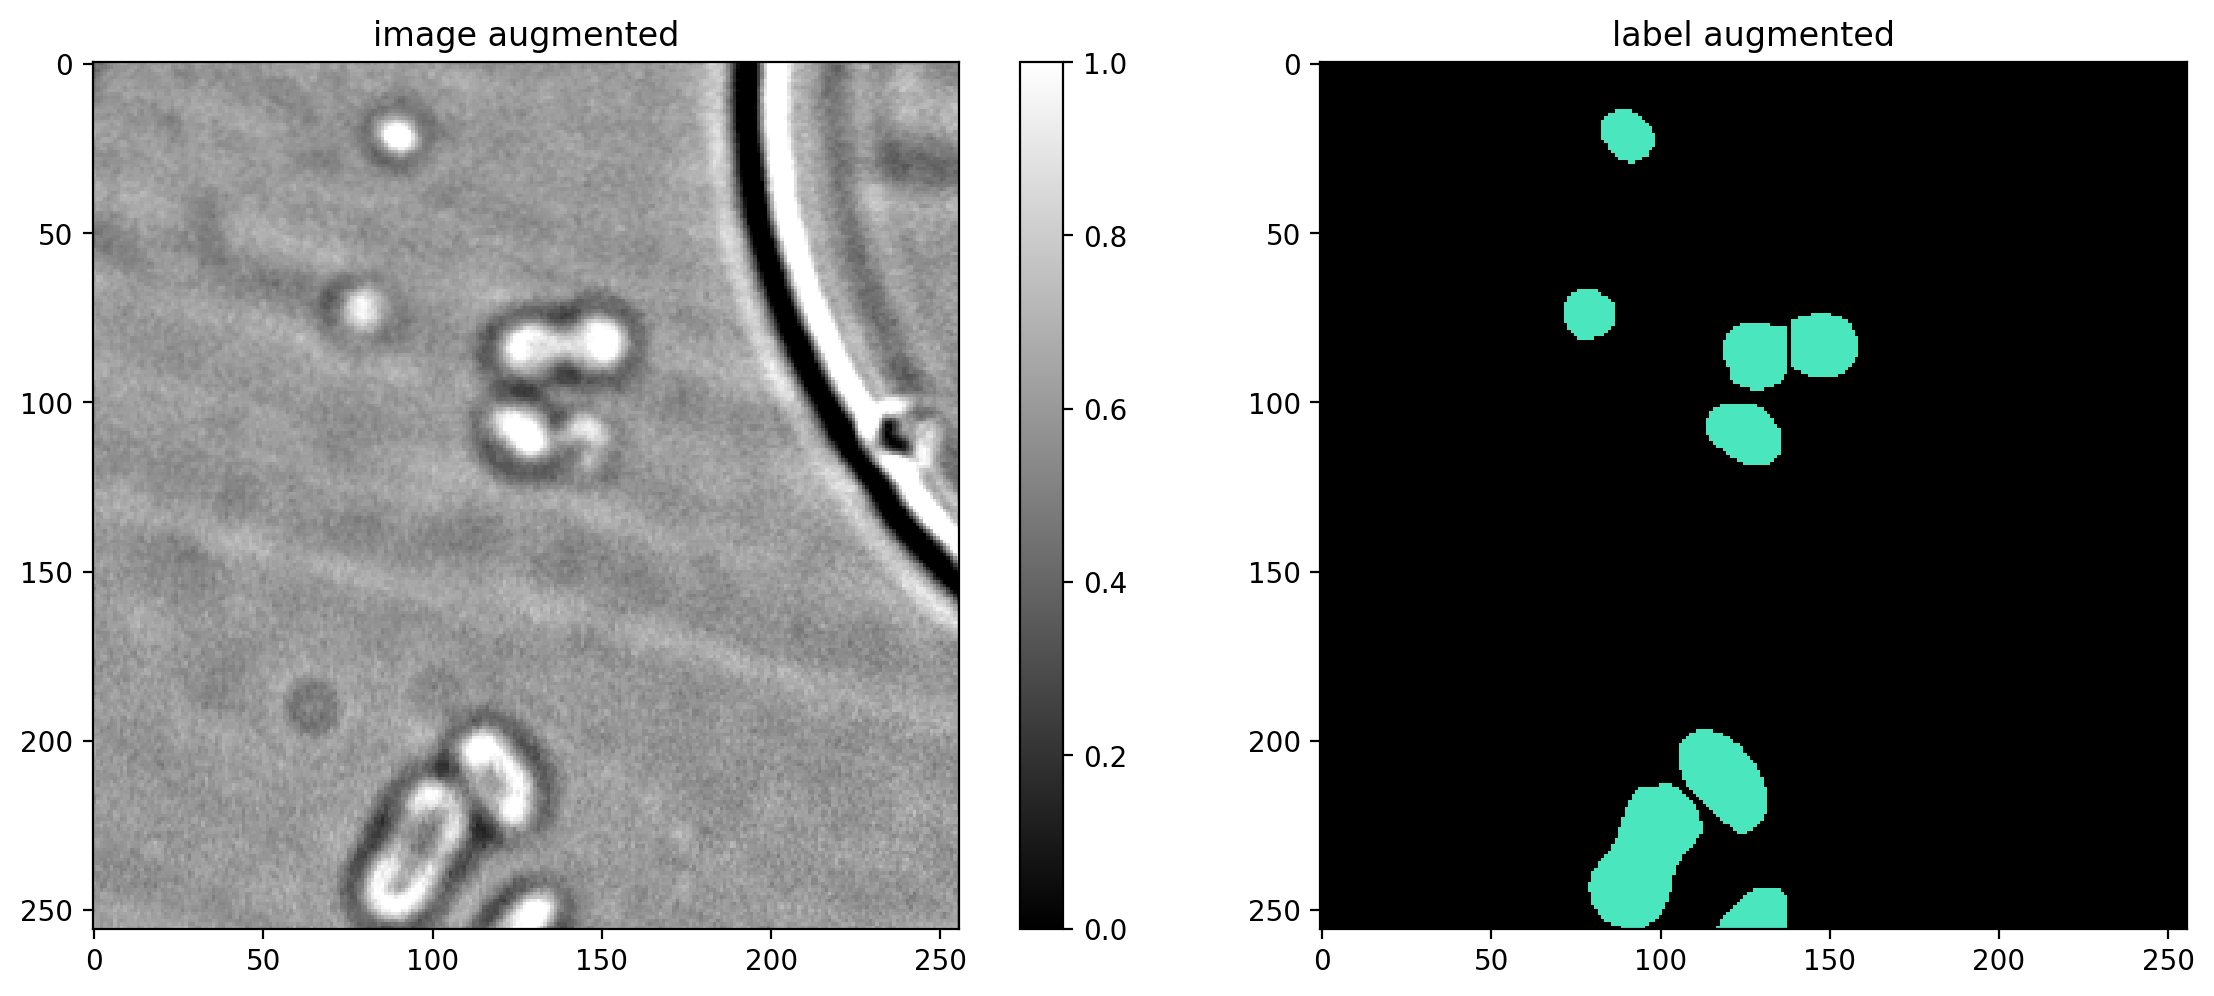

In [14]:
# Visualize the original image and label
img, lbl = X[0],Y[0]
plot_img_label(img, lbl)

for _ in range(3):
    img_aug, lbl_aug = augmenter(img,lbl)
    plot_img_label(img_aug, lbl_aug, img_title="image augmented", lbl_title="label augmented")

## 5. Training

We recommend to monitor the progress during training with [TensorBoard](https://www.tensorflow.org/programmers_guide/summaries_and_tensorboard). You can start it in the shell from the current working directory like this:

    $ tensorboard --logdir=.

Then connect to [http://localhost:6006/](http://localhost:6006/) with your browser.


In [ ]:
quick_demo = False

if quick_demo:
    print (
        "NOTE: This is only for a quick demonstration!\n"
        "      Please set the variable 'quick_demo = False' for proper (long) training.",
        file=sys.stderr, flush=True
    )
    model.train(X_trn, Y_trn, validation_data=(X_val,Y_val), augmenter=augmenter,
                epochs=2, steps_per_epoch=10)

    print("====> Stopping training and loading previously trained demo model from disk.", file=sys.stderr, flush=True)
    model = StarDist2D.from_pretrained('2D_demo')
else:
    model.train(X_trn, Y_trn, validation_data=(X_val,Y_val), augmenter=augmenter)
None;

## 6. Threshold optimization

While the default values for the probability and non-maximum suppression thresholds already yield good results in many cases, we still recommend to adapt the thresholds to your data. The optimized threshold values are saved to disk and will be automatically loaded with the model.

In [ ]:
if quick_demo:
    model.optimize_thresholds(X_val[:2], Y_val[:2])
else:
    model.optimize_thresholds(X_val, Y_val)

NMS threshold = 0.5:  75%|███████▌  | 15/20 [00:01<00:00,  7.87it/s, 0.582 -> 0.011]


Using optimized values: prob_thresh=0.584677, nms_thresh=0.3.
Saving to 'thresholds.json'.


## 7. Evaluation and Detection Performance

Besides the losses and metrics during training, we can also quantitatively evaluate the actual detection/segmentation performance on the validation data by considering objects in the ground truth to be correctly matched if there are predicted objects with overlap (here [intersection over union (IoU)](https://en.wikipedia.org/wiki/Jaccard_index)) beyond a chosen IoU threshold $\tau$.

The corresponding matching statistics (average overlap, accuracy, recall, precision, etc.) are typically of greater practical relevance than the losses/metrics computed during training (but harder to formulate as a loss function). 
The value of $\tau$ can be between 0 (even slightly overlapping objects count as correctly predicted) and 1 (only pixel-perfectly overlapping objects count) and which $\tau$ to use depends on the needed segmentation precision/application.

Please see `help(matching)` for definitions of the abbreviations used in the evaluation below and see the Wikipedia page on [Sensitivity and specificity](https://en.wikipedia.org/wiki/Sensitivity_and_specificity) for further details.

In [ ]:
# help(matching)

First predict the labels for all validation images:

In [ ]:
# Predict instance segmentation masks for the validation images using the trained model
Y_val_pred = [model.predict_instances(x, n_tiles=model._guess_n_tiles(x), show_tile_progress=False)[0]
              for x in tqdm(X_val)]

100%|██████████| 65/65 [00:03<00:00, 21.53it/s]


Plot a GT/prediction example 

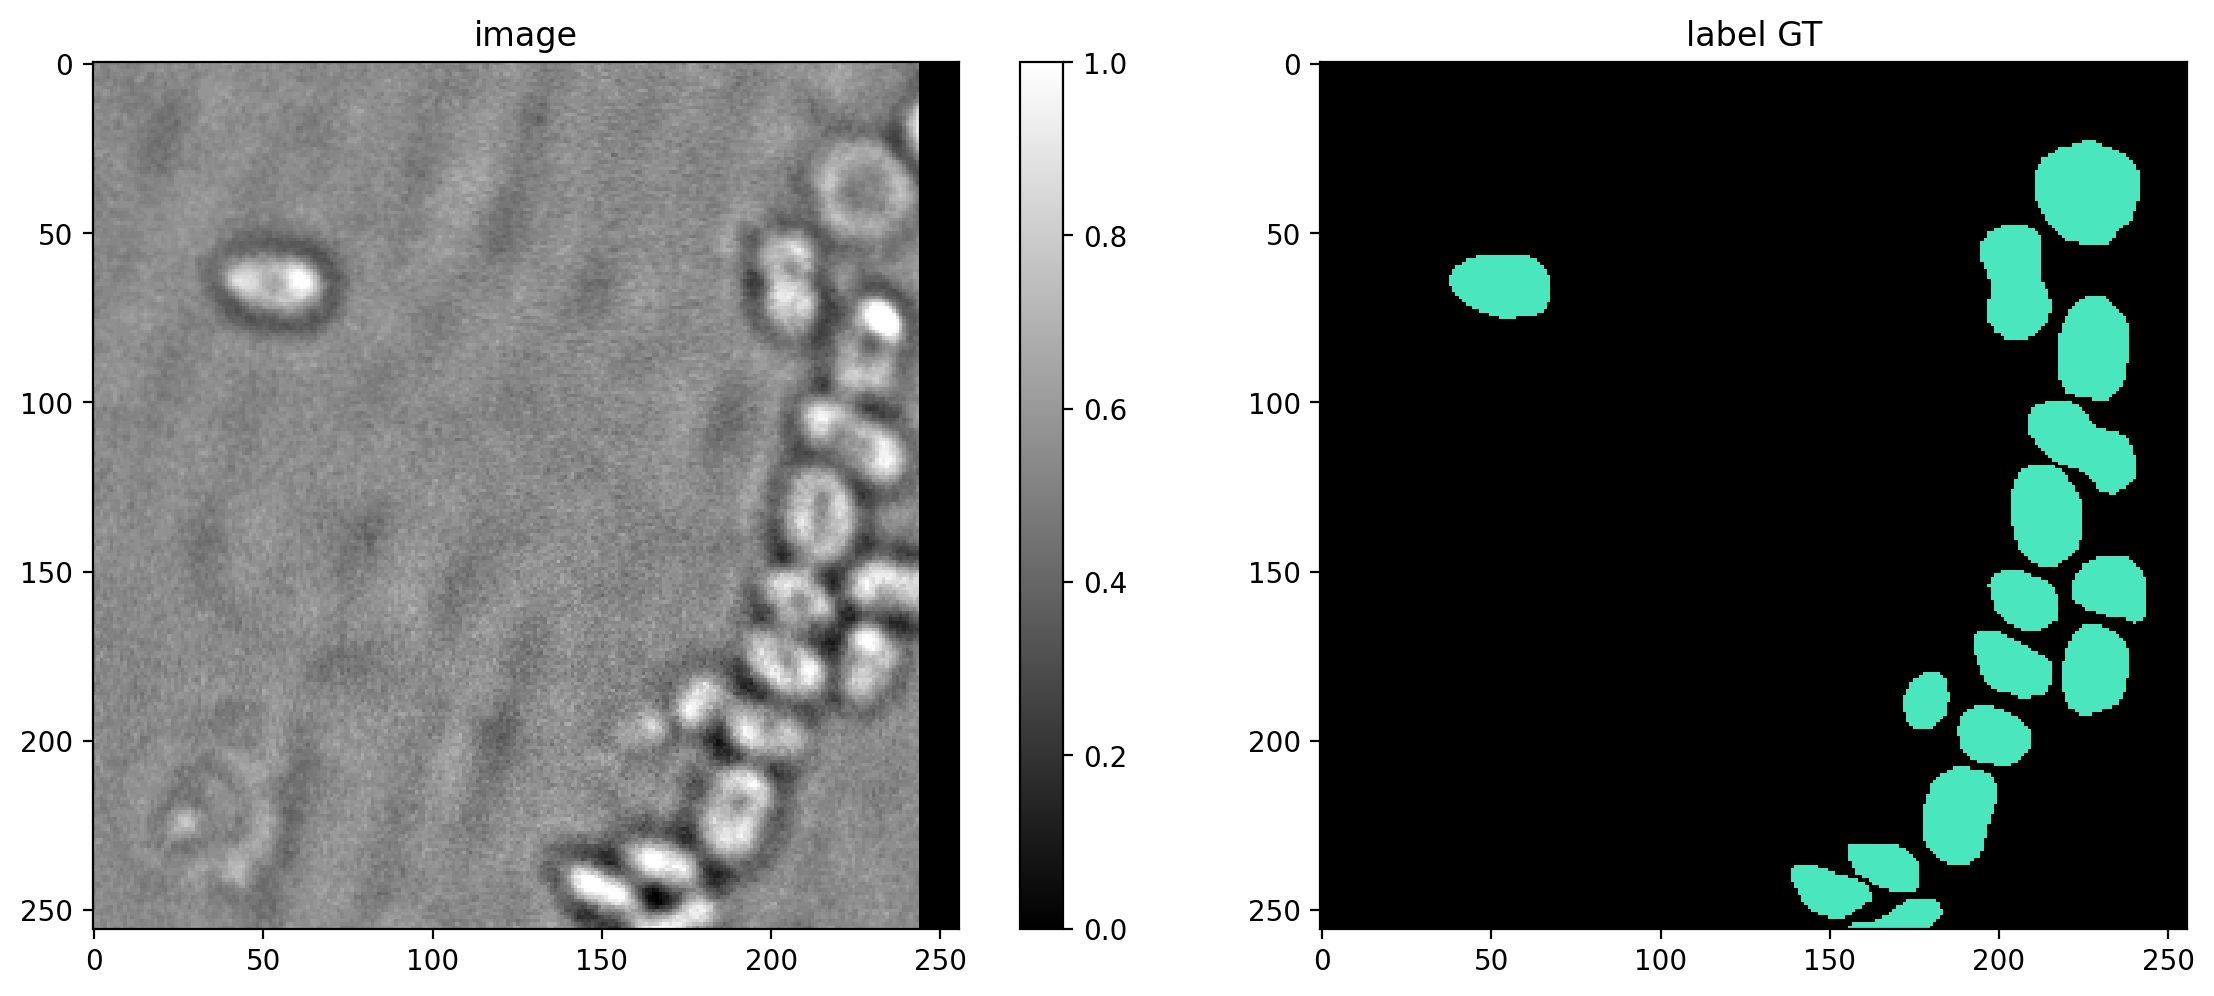

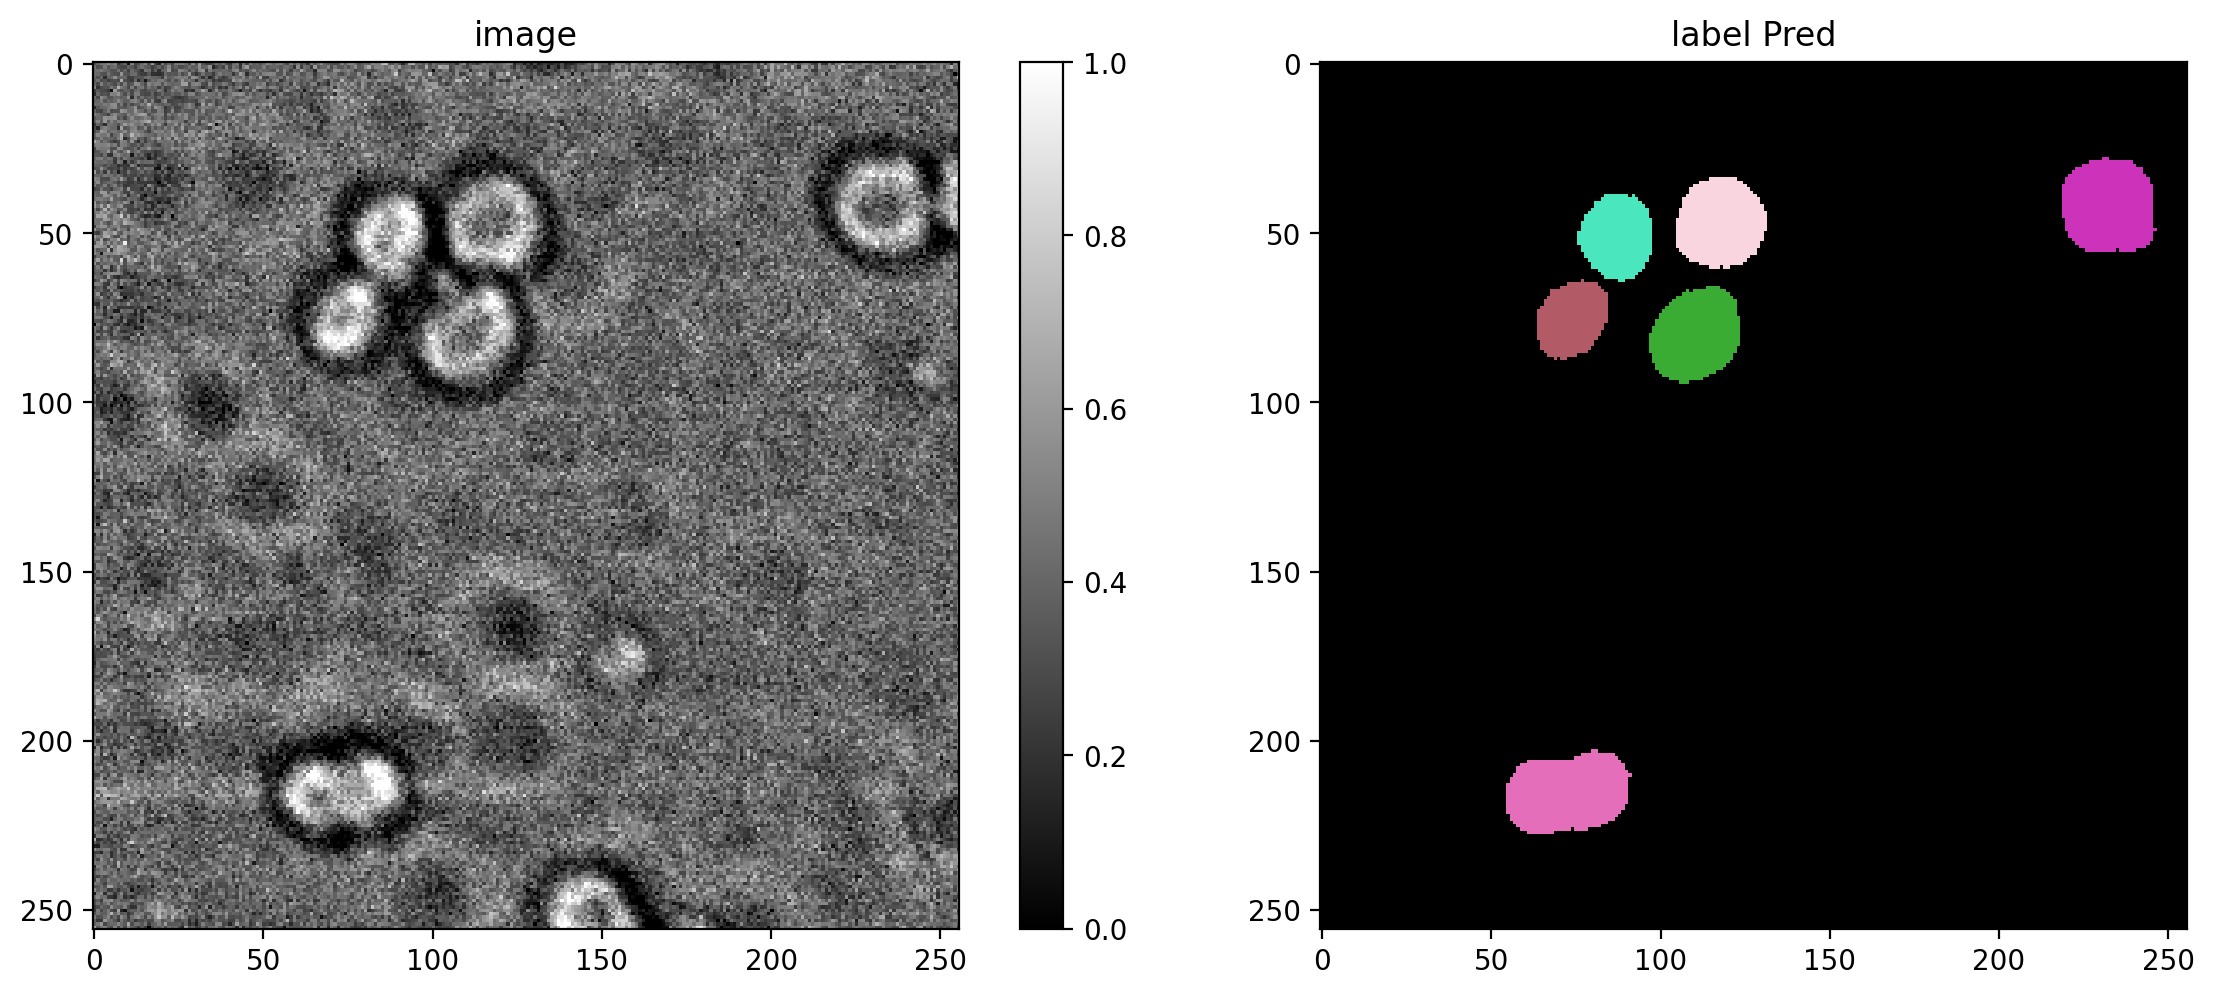

In [ ]:
# Display a validation image and its ground-truth label
plot_img_label(X_val[0],Y_val[0], lbl_title="label GT")

# Display a validation image and its predicted label
plot_img_label(X_val[4],Y_val_pred[4], lbl_title="label Pred")

Choose several IoU thresholds $\tau$ that might be of interest and for each compute matching statistics for the validation data.

In [ ]:
taus = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9] 
stats = [matching_dataset(Y_val, Y_val_pred, thresh=t, show_progress=False) for t in tqdm(taus)] 

100%|██████████| 9/9 [00:00<00:00,  9.39it/s]


Example: Print all available matching statistics for $\tau=0.5$

In [ ]:
stats[taus.index(0.5)]

DatasetMatching(criterion='iou', thresh=0.5, fp=474, tp=3, fn=62, precision=0.006289308176100629, recall=0.046153846153846156, accuracy=0.0055658627087198514, f1=0.01107011070110701, n_true=65, n_pred=477, mean_true_score=0.03379751902360183, mean_matched_score=0.7322795788447062, panoptic_quality=0.008106416001970918, by_image=False)

Plot the matching statistics and the number of true/false positives/negatives as a function of the IoU threshold $\tau$. 

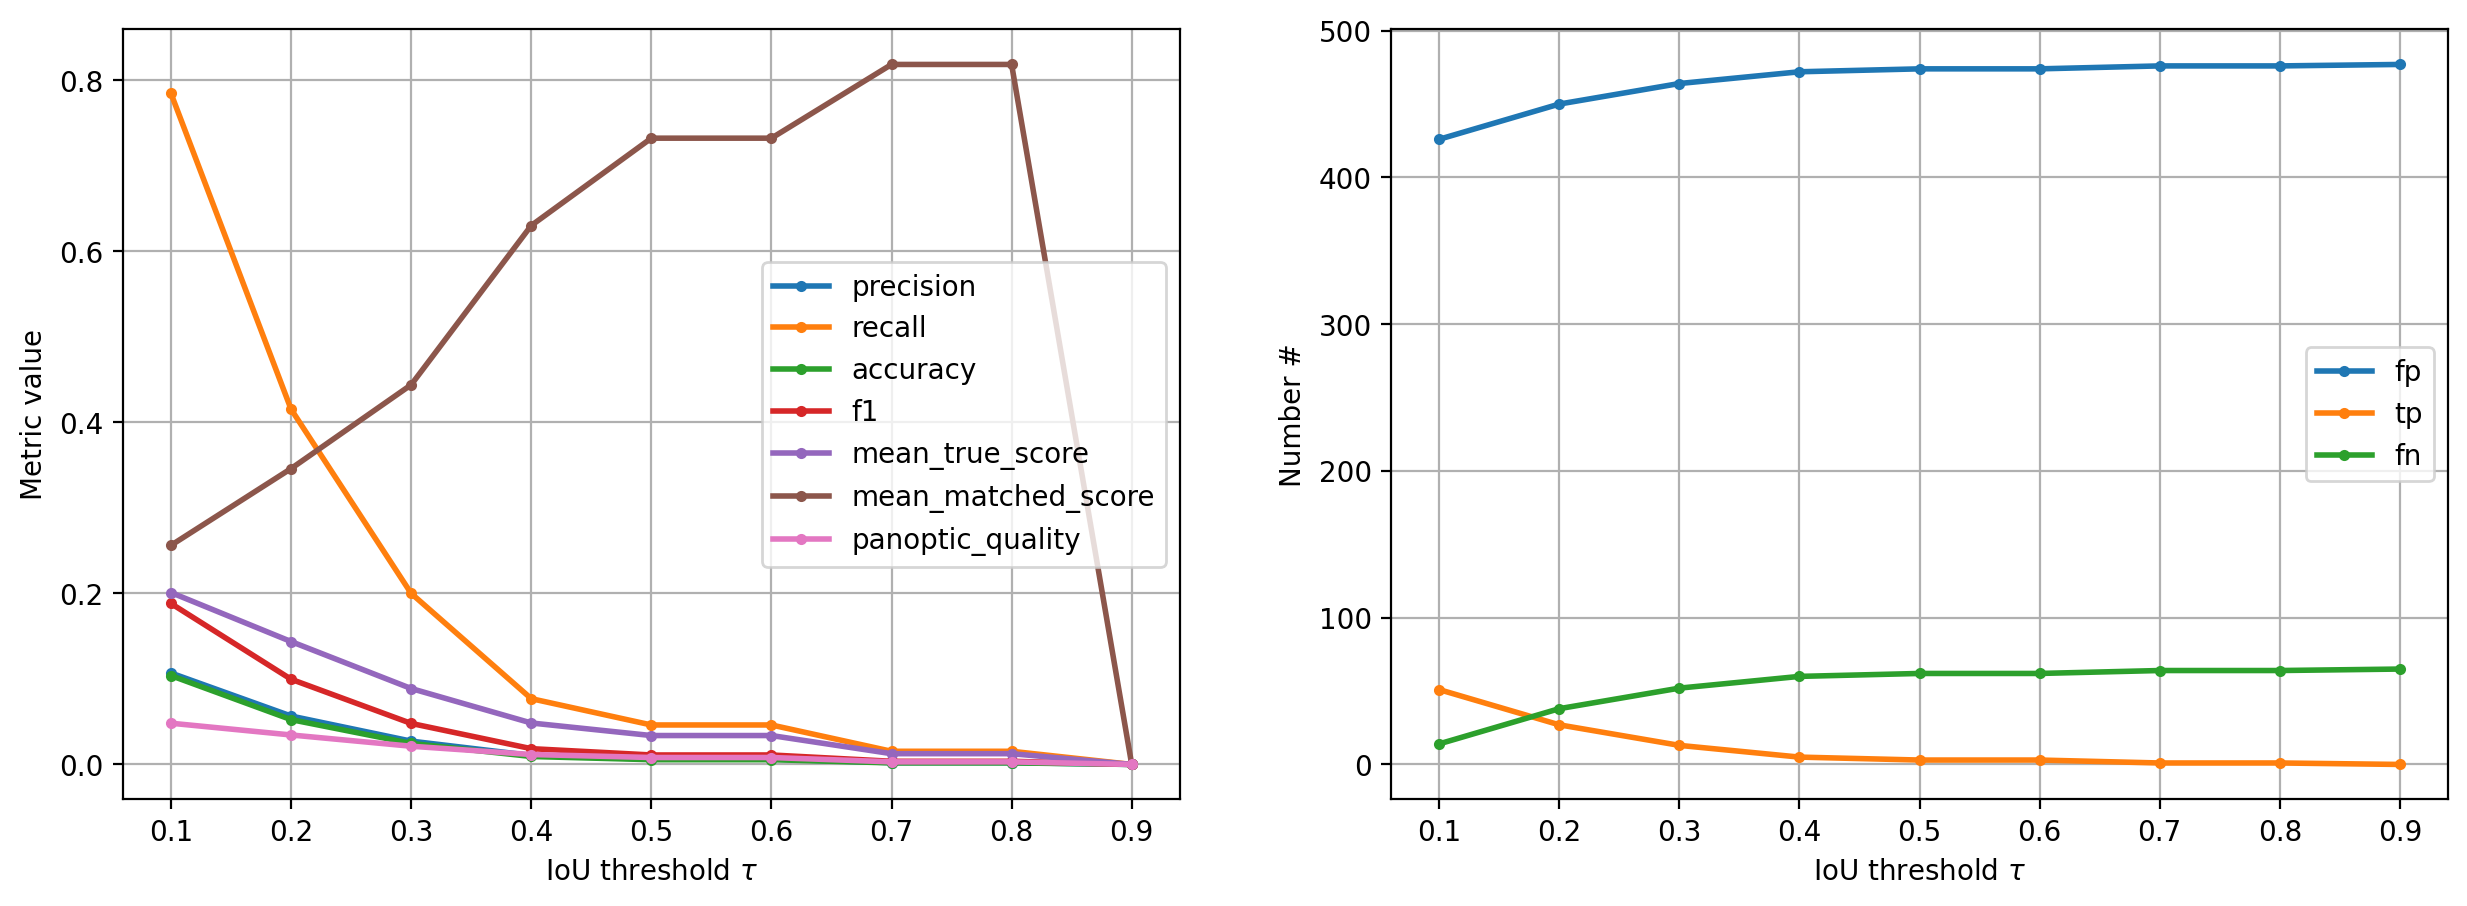

In [ ]:
fig, (ax1,ax2) = plt.subplots(1,2, figsize=(15,5))

# Plot evaluation metrics against the IoU threshold
for m in ('precision', 'recall', 'accuracy', 'f1', 'mean_true_score', 'mean_matched_score', 'panoptic_quality'):
    ax1.plot(taus, [s._asdict()[m] for s in stats], '.-', lw=2, label=m)
ax1.set_xlabel(r'IoU threshold $\tau$')
ax1.set_ylabel('Metric value')
ax1.grid()
ax1.legend()

# Plot the numbers of false positives (FP), true positives (TP), and false negatives (FN) against the IoU threshold
for m in ('fp', 'tp', 'fn'):
    ax2.plot(taus, [s._asdict()[m] for s in stats], '.-', lw=2, label=m)
ax2.set_xlabel(r'IoU threshold $\tau$')
ax2.set_ylabel('Number #')
ax2.grid()
ax2.legend();